# Análise exploratória: receita e desempenho dos clubes no Brasileirão (2007-2024)

Base: Campeonato BR 2007-2024 Financeiro (Kaggle).

In [1]:
import sys
sys.path.append('..')

import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
from src import etl

pd.set_option('display.max_columns', 40)

## 1. Carregando e tratando os dados

In [2]:
df = etl.executar()
df.head()

Linhas e colunas do arquivo original: (302, 18)
Valores nulos por coluna: 0
Linhas duplicadas: 0
Clubes com número de jogos diferente de 38:
      ano        clube  jogos
150  2016  Atlético-MG     37
152  2016  Chapecoense     37
Clubes com pontuação diferente de 3V + E:
      ano     clube  vitorias  empates  pontos
106  2013  Flamengo        12       13      45
Arquivo tratado salvo com 302 linhas e 30 colunas


,ano,posicao,clube,vitorias,empates,derrotas,gols_feitos,gols_sofridos,saldo_gols,pontos,receita,resultado_financeiro,qtd_jogadores,idade_media,estrangeiros,valor_medio_jogador,valor_elenco,campeao,jogos,jogos_diferente_de_38,pontos_nao_batem,aproveitamento,receita_relativa,ranking_receita,teve_superavit,margem_financeira,faixa_receita,superavit_ano_anterior,aproveitamento_ano_anterior,variacao_aproveitamento
0,2007,1,São Paulo,23,8,7,55,19,36,77,190.0,3.8,43,23.4,3,0.470,20.20,True,38,False,False,67.5,3.65,1,True,2.0,4 - maior,NaN,<NA>,<NA>
1,2007,2,Santos,19,5,14,57,47,10,62,53.1,-36.6,51,24.1,6,0.486,24.80,False,38,False,False,54.4,1.02,9,False,-68.9,3,NaN,<NA>,<NA>
2,2007,3,Flamengo,17,10,11,55,49,6,61,89.4,-59.2,42,23.2,2,0.374,15.73,False,38,False,False,53.5,1.72,5,False,-66.2,4 - maior,NaN,<NA>,<NA>
3,2007,4,Fluminense,16,13,9,57,39,18,61,39.3,-139.4,39,23.0,0,0.527,20.55,False,38,False,False,53.5,0.76,13,False,-354.7,2,NaN,<NA>,<NA>
4,2007,5,Cruzeiro,18,6,14,73,58,15,60,77.6,-2.8,53,22.4,1,0.256,13.55,False,38,False,False,52.6,1.49,7,False,-3.6,3,NaN,<NA>,<NA>


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 302 entries, 0 to 301
Data columns (total 30 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ano                          302 non-null    Int64  
 1   posicao                      302 non-null    Int64  
 2   clube                        302 non-null    str    
 3   vitorias                     302 non-null    Int64  
 4   empates                      302 non-null    Int64  
 5   derrotas                     302 non-null    Int64  
 6   gols_feitos                  302 non-null    Int64  
 7   gols_sofridos                302 non-null    Int64  
 8   saldo_gols                   302 non-null    Int64  
 9   pontos                       302 non-null    Int64  
 10  receita                      302 non-null    float64
 11  resultado_financeiro         302 non-null    float64
 12  qtd_jogadores                302 non-null    Int64  
 13  idade_media                  30

## 2. Estatística descritiva

In [4]:
colunas = ['pontos', 'aproveitamento', 'gols_feitos', 'gols_sofridos', 'receita', 'resultado_financeiro', 'valor_elenco', 'idade_media', 'estrangeiros']
descricao = df[colunas].describe().T
descricao['coef_variacao'] = descricao['std'] / descricao['mean']
descricao.round(2)

,count,mean,std,min,25%,50%,75%,max,coef_variacao
pontos,302.0,53.745033,11.645849,17.0,46.0,53.0,61.75,90.0,0.216687
aproveitamento,302.0,47.156623,10.218143,14.9,40.4,46.5,54.175,78.9,0.216685
gols_feitos,302.0,48.129139,10.484915,22.0,41.0,48.0,56.0,86.0,0.21785
gols_sofridos,302.0,45.642384,9.821222,19.0,39.0,45.0,51.0,81.0,0.215178
receita,302.0,252.280795,239.808025,12.4,87.725,181.95,332.9,1374.0,0.95056
resultado_financeiro,302.0,-7.860563,76.44259,-394.1,-27.025,-3.45,8.45,383.2,-9.724824
valor_elenco,302.0,52.945166,37.477096,1.0,24.7475,44.9,71.625,214.15,0.707847
idade_media,302.0,23.519205,0.884358,21.4,23.0,23.5,24.075,26.3,0.037602
estrangeiros,302.0,4.801325,2.862334,0.0,2.0,5.0,7.0,14.0,0.596155


In [5]:
por_ano = df.groupby('ano').agg(clubes=('clube', 'count'), receita_total=('receita', 'sum'), receita_mediana=('receita', 'median'))
por_ano['participacao_4_maiores'] = df.groupby('ano')['receita'].apply(lambda r: r.nlargest(4).sum() / r.sum()).round(3)
por_ano

,clubes,receita_total,receita_mediana,participacao_4_maiores
ano,,,,
2007,18,1217.2,52.05,0.484
2008,16,1197.5,61.45,0.467
2009,16,1394.3,68.20,0.471
2010,16,1650.4,97.25,0.459
2011,16,2063.5,132.90,0.438
2012,17,2822.9,151.20,0.408
2013,17,2853.0,159.70,0.431
2014,18,2842.5,167.30,0.390
2015,16,3323.6,191.15,0.422


## 3. Outliers (regra do intervalo interquartil)

In [6]:
def outliers(coluna):
    q1 = df[coluna].quantile(0.25)
    q3 = df[coluna].quantile(0.75)
    iiq = q3 - q1
    return df[(df[coluna] < q1 - 1.5 * iiq) | (df[coluna] > q3 + 1.5 * iiq)]

outliers('resultado_financeiro')[['ano', 'clube', 'receita', 'resultado_financeiro', 'posicao']].sort_values('resultado_financeiro')

,ano,clube,receita,resultado_financeiro,posicao
216,2019,Cruzeiro,280.8,-394.10,17
286,2024,Botafogo,719.7,-300.00,1
291,2024,São Paulo,731.9,-287.00,6
32,2008,Vasco da Gama,52.0,-276.80,18
293,2024,Bahia,273.3,-246.50,8
292,2024,Corinthians,1115.0,-181.70,7
207,2019,Corinthians,425.7,-177.00,8
132,2014,Botafogo,163.4,-174.80,19
294,2024,Cruzeiro,307.6,-169.90,9
74,2011,Botafogo,58.9,-166.60,9


In [7]:
outliers('receita_relativa')[['ano', 'clube', 'receita', 'receita_relativa']]

,ano,clube,receita,receita_relativa
0,2007,São Paulo,190.0,3.65
256,2022,Flamengo,1177.0,3.51
271,2023,Flamengo,1374.0,3.13


## 4. Correlações

In [8]:
variaveis = {'aproveitamento': 'Aproveitamento', 'gols_feitos': 'Gols feitos', 'gols_sofridos': 'Gols sofridos', 'receita_relativa': 'Receita relativa', 'valor_elenco': 'Valor do elenco', 'margem_financeira': 'Margem financeira', 'idade_media': 'Idade média', 'estrangeiros': 'Estrangeiros'}
correlacao = df[list(variaveis)].rename(columns=variaveis).corr(method='spearman').round(2)
correlacao

,Aproveitamento,Gols feitos,Gols sofridos,Receita relativa,Valor do elenco,Margem financeira,Idade média,Estrangeiros
Aproveitamento,1.00,0.75,-0.64,0.59,0.41,0.05,-0.05,0.20
Gols feitos,0.75,1.00,-0.14,0.44,0.22,-0.08,-0.03,0.06
Gols sofridos,-0.64,-0.14,1.00,-0.43,-0.40,-0.16,0.04,-0.22
Receita relativa,0.59,0.44,-0.43,1.00,0.63,0.17,-0.14,0.41
Valor do elenco,0.41,0.22,-0.40,0.63,1.00,0.10,-0.04,0.60
Margem financeira,0.05,-0.08,-0.16,0.17,0.10,1.00,0.04,0.05
Idade média,-0.05,-0.03,0.04,-0.14,-0.04,0.04,1.00,-0.06
Estrangeiros,0.20,0.06,-0.22,0.41,0.60,0.05,-0.06,1.00


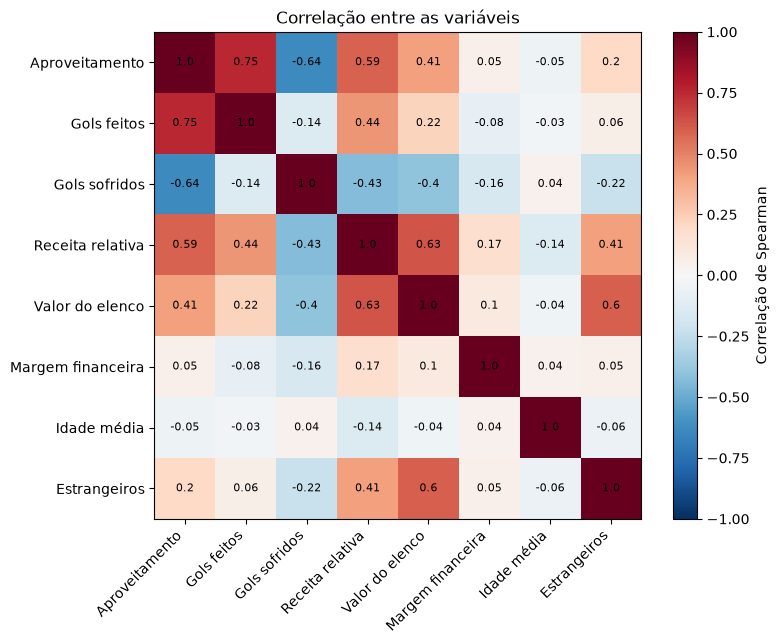

In [9]:
fig, ax = plt.subplots(figsize=(8, 6.5))
imagem = ax.imshow(correlacao, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(correlacao)), correlacao.columns, rotation=45, ha='right')
ax.set_yticks(range(len(correlacao)), correlacao.index)
for i in range(len(correlacao)):
    for j in range(len(correlacao)):
        ax.text(j, i, correlacao.iloc[i, j], ha='center', va='center', fontsize=8)
fig.colorbar(imagem, label='Correlação de Spearman')
ax.set_title('Correlação entre as variáveis')
plt.tight_layout()
plt.savefig('../docs/assets/correlacao.png', dpi=150)
plt.show()

## 5. RQ1 - Clubes com mais receita fazem mais pontos?

In [10]:
df['receita_relativa'].corr(df['aproveitamento'], method='spearman').round(2)

np.float64(0.59)

In [11]:
faixas = df.groupby('faixa_receita').agg(
    participacoes=('clube', 'count'),
    aproveitamento_medio=('aproveitamento', 'mean'),
    pct_g4=('posicao', lambda p: (p <= 4).mean() * 100),
    pct_rebaixados=('posicao', lambda p: (p >= 17).mean() * 100),
    titulos=('campeao', 'sum'),
).round(1)
faixas

,participacoes,aproveitamento_medio,pct_g4,pct_rebaixados,titulos
faixa_receita,,,,,
1 - menor,81,39.4,1.2,30.9,0
2,72,44.0,11.1,22.2,2
3,72,52.7,41.7,0.0,5
4 - maior,77,53.1,41.6,3.9,11


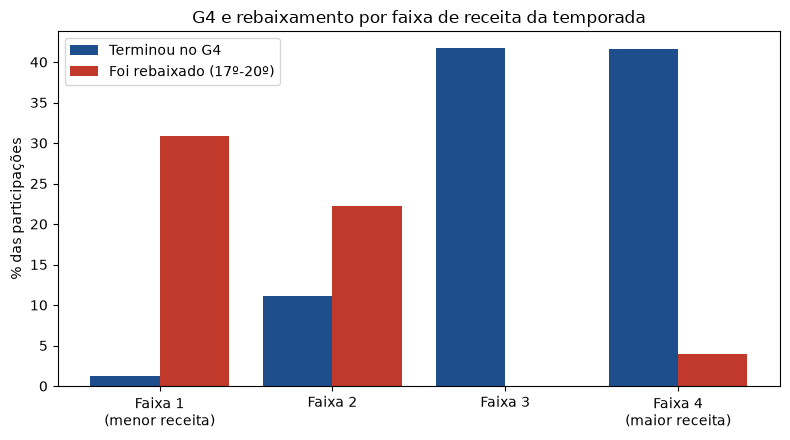

In [12]:
fig, ax = plt.subplots(figsize=(8, 4.5))
x = range(len(faixas))
ax.bar([i - 0.2 for i in x], faixas['pct_g4'], width=0.4, label='Terminou no G4', color='#1f4e8c')
ax.bar([i + 0.2 for i in x], faixas['pct_rebaixados'], width=0.4, label='Foi rebaixado (17º-20º)', color='#c0392b')
ax.set_xticks(list(x), ['Faixa 1\n(menor receita)', 'Faixa 2', 'Faixa 3', 'Faixa 4\n(maior receita)'])
ax.set_ylabel('% das participações')
ax.set_title('G4 e rebaixamento por faixa de receita da temporada')
ax.legend()
plt.tight_layout()
plt.savefig('../docs/assets/faixas_receita.png', dpi=150)
plt.show()

In [13]:
grafico = px.scatter(
    df.assign(campeao=df['campeao'].map({True: 'Sim', False: 'Não'})), x='receita_relativa', y='aproveitamento', color='campeao', hover_data=['clube', 'ano', 'posicao'],
    log_x=True, trendline=None,
    labels={'receita_relativa': 'Receita relativa à mediana do ano (escala log)', 'aproveitamento': 'Aproveitamento (%)', 'campeao': 'Campeão'},
    color_discrete_map={'Não': '#8fb3e0', 'Sim': '#e67e22'},
    title='Receita relativa x aproveitamento',
)
grafico.write_html('../docs/assets/receita_aproveitamento.html', include_plotlyjs='cdn')
grafico

In [14]:
campeoes = df[df['campeao']][['ano', 'clube', 'pontos', 'receita', 'ranking_receita']]
print('Campeões entre as 3 maiores receitas:', (campeoes['ranking_receita'] <= 3).sum(), 'de', len(campeoes))
print('Campeões entre as 5 maiores receitas:', (campeoes['ranking_receita'] <= 5).sum(), 'de', len(campeoes))
campeoes

Campeões entre as 3 maiores receitas: 9 de 18
Campeões entre as 5 maiores receitas: 14 de 18


,ano,clube,pontos,receita,ranking_receita
0,2007,São Paulo,77,190.0,1
18,2008,São Paulo,75,160.5,1
34,2009,Flamengo,67,120.0,6
50,2010,Fluminense,71,76.8,11
66,2011,Corinthians,71,290.5,1
82,2012,Fluminense,77,151.2,9
99,2013,Cruzeiro,76,187.9,8
116,2014,Cruzeiro,80,223.2,5
134,2015,Corinthians,81,298.4,5
150,2016,Palmeiras,80,497.7,2


In [15]:
grafico = px.bar(
    campeoes, x='ano', y='ranking_receita', hover_data=['clube', 'receita'], text='clube',
    labels={'ano': 'Temporada', 'ranking_receita': 'Posição no ranking de receita'},
    title='Posição do campeão no ranking de receita (1 = mais rico)',
)
grafico.update_traces(marker_color='#1f4e8c', textposition='outside', textfont_size=9)
grafico.update_yaxes(range=[0, 13])
grafico.write_html('../docs/assets/ranking_campeoes.html', include_plotlyjs='cdn')
grafico

## 6. RQ2 - Ter superávit está ligado a um desempenho melhor?

In [16]:
df.groupby('teve_superavit')['aproveitamento'].agg(['count', 'mean', 'median']).round(1)

,count,mean,median
teve_superavit,,,
False,174,46.2,45.6
True,128,48.5,46.5


In [17]:
seguidos = df.dropna(subset=['superavit_ano_anterior'])
seguidos.groupby('superavit_ano_anterior')['variacao_aproveitamento'].agg(['count', 'mean', 'median']).round(1)

,count,mean,median
superavit_ano_anterior,,,
False,133,-1.6,-1.7
True,104,-1.8,-2.7


In [18]:
print('Correlação margem financeira x aproveitamento:', df['margem_financeira'].corr(df['aproveitamento'], method='spearman').round(2))
print('Correlação aproveitamento do ano anterior x variação:', seguidos['aproveitamento_ano_anterior'].corr(seguidos['variacao_aproveitamento'], method='spearman').round(2))

Correlação margem financeira x aproveitamento: 0.05
Correlação aproveitamento do ano anterior x variação: -0.41


In [19]:
seguidos = seguidos.assign(situacao=seguidos['superavit_ano_anterior'].map({True: 'Superávit no ano anterior', False: 'Déficit no ano anterior'}))
grafico = px.box(
    seguidos, x='situacao', y='variacao_aproveitamento', points='all', hover_data=['clube', 'ano'], color='situacao',
    color_discrete_map={'Superávit no ano anterior': '#27ae60', 'Déficit no ano anterior': '#c0392b'},
    labels={'situacao': '', 'variacao_aproveitamento': 'Variação do aproveitamento (pontos percentuais)'},
    title='Variação do aproveitamento de um ano para o outro',
)
grafico.update_layout(showlegend=False)
grafico.write_html('../docs/assets/superavit_variacao.html', include_plotlyjs='cdn')
grafico